---
title: "From Score Matching to Diffusion Models"
author: "Mark Fuge"
date: "November 9th, 2025"
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

In the previous chapter, we introduced Denoising Score Matching (DSM) as a way to learn a generative vector field, the **score function** $\nabla_x \log p(x)$, without the computationally expensive trace term that plagued Continuous Normalizing Flows. We used this learned score to generate samples via Langevin Dynamics, which follows the score field uphill while adding noise to explore the data distribution.

However, this approach has its own limitations. The score function is only well-defined and easy to learn *near* the data. Far from the data manifold, where there are no samples, the score can be chaotic or undefined, making it difficult to initialize a generative process from random noise. Furthermore, we had to choose a single, fixed noise level $\sigma$ for training, which created a trade-off: too much noise and we lose important details; too little and the score is hard to learn.

This chapter introduces **Diffusion Models**, which solve these problems by learning a score function not just for one noise level, but for a *continuum* of noise levels. This creates a robust, time-dependent vector field that can smoothly transform pure noise into structured data.

## Learning Objectives

By the end of this chapter, you should be able to:

1. Write down the forward process $x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$ and explain how the noise schedule sets how much of the data is left at $t = T$.
2. Explain why one network can learn the score at every noise level only if we give it $t$. Explain how predicting $\epsilon$ relates to the score and to denoising.
3. Explain reverse diffusion as annealed Langevin sampling that goes from coarse to fine.
4. Diagnose a diffusion model from its training loss, its loss at each noise level and snapshots of its reverse process.
5. Condition a diffusion model on a discrete or continuous variable by adding that variable to the network input.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
import torch.optim as optim
from gen_models_utilities import create_ring_gaussians, make_loader, load_eth_z_logo_data
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Use a consistent style
plt.style.use('seaborn-v0_8-muted')
sns.set_context('talk')

# for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = "cpu"
print(f'Using device: {device}')

data, _ = create_ring_gaussians(n_samples=5000)
#data = load_eth_z_logo_data(n_samples=5000)

Using device: cpu


## Why Go Beyond Single-Noise Score Matching?

Let's first revisit the limitations of the score model we trained in the previous chapter. That model learned the score function for a *single* noise level, $\sigma$. This meant trading off detail and stability: a small $\sigma$ captures fine details but is hard to learn, while a large $\sigma$ smooths out the data but loses the ability to describe higher-frequency contours of the true log probability.

The key idea behind diffusion models is that they fix this problem by defining a continuum of noisy data distributions $p_t(x)$, which are smooth and well-behaved everywhere, even far from the data, yet can still create score functions that capture fine details when $t$ is small.

In [2]:
# The same ScoreNet2D as in the previous chapter
class ScoreNet2D(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.Softplus(),
            nn.Linear(hidden, hidden),
            nn.Softplus(),
            nn.Linear(hidden, 2)
        )

    def forward(self, x):
        return self.net(x)

# A simplified version of the training function from the previous chapter.
# x_tilde = sqrt(alpha_bar) * x + sigma * eps; alpha_bar = 1 gives the previous chapter's noisy data,
# alpha_bar < 1 gives the samples x_t of the forward process introduced below.
def train_simple_score_net(sigma=0.5, alpha_bar=1.0, n_epochs=100, batch_size=256):
    loader = make_loader(data, batch_size=batch_size)
    score_net = ScoreNet2D().to(device)
    optimizer = optim.AdamW(score_net.parameters(), lr=1e-3)
    for epoch in range(n_epochs):
        for (x,) in loader:
            x = x.to(device)
            noise = torch.randn_like(x) * sigma
            x_tilde = alpha_bar**0.5 * x + noise
            predicted_score = score_net(x_tilde)
            target_score = -noise / (sigma**2)
            loss = ((predicted_score - target_score)**2).mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    print(f"Finished training score network with sigma={sigma:.3f}")
    return score_net

# Train a score network with a high noise level
noise_level = 5.0
score_net_simple = train_simple_score_net(sigma=noise_level)


Finished training score network with sigma=5.000


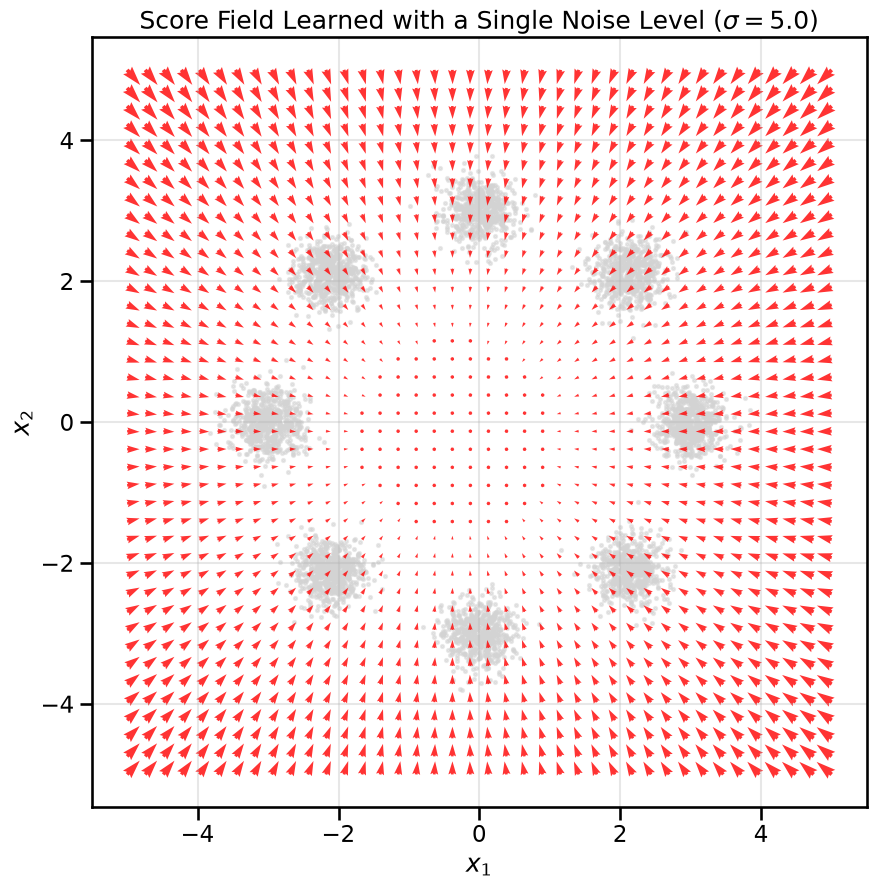

In [3]:
# Create a grid to visualize the score field
xx, yy = np.meshgrid(np.linspace(-5, 5, 40), np.linspace(-5, 5, 40))
grid_points = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32, device=device)

# Get the score at each grid point
score_net_simple.eval()
with torch.no_grad():
    scores = score_net_simple(grid_points).cpu().numpy()

# Plot the results
plt.figure(figsize=(10, 10))
#sns.kdeplot(x=data[:, 0], y=data[:, 1], cmap="viridis", fill=True, alpha=0.5, levels=20)
plt.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', alpha=0.5)
plt.quiver(grid_points[:, 0].cpu(), grid_points[:, 1].cpu(), scores[:, 0], scores[:, 1], color='red', width=0.005, alpha=0.8)
plt.title(rf"Score Field Learned with a Single Noise Level ($\sigma={noise_level}$)")
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.show()

## The Forward Diffusion Process $q(x_t|x_0)$

The first key component of a diffusion model is the **forward process**, where we systematically destroy the structure in our data by gradually adding Gaussian noise over a series of timesteps. We define a "noise schedule" that controls how much noise is added at each step.

Let $x_0$ be a sample from our data distribution. The forward process $q(x_t|x_0)$ defines a noisy version of this sample at time $t$:

$$ x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, \quad \epsilon \sim \mathcal{N}(0, I) $$

Here, $\bar{\alpha}_t$ is a parameter that goes from 1 down to (almost) 0 as $t$ goes from 0 to $T$. 
- When $t=0$, $\bar{\alpha}_0 = 1$, so $x_0$ is just the original data.
- As $t$ increases, $\bar{\alpha}_t$ decreases, and more noise is added.
- When $t=T$ is large, $\bar{\alpha}_T \approx 0$, so $x_T$ is almost pure Gaussian noise.

We use $T = 200$ steps. The noise per step, $\beta_t$, rises linearly from $10^{-4}$ to $0.1$ -- this is referred to as the noise schedule, and $\bar{\alpha}_t = \prod_{s \le t} (1 - \beta_s)$. This gives $\bar{\alpha}_T \approx 3 \cdot 10^{-5}$, so $x_T$ keeps only $\sqrt{\bar{\alpha}_T} \approx 0.006$ of $x_0$ after completing the forward process. In the code, the schedule arrays run from index 0 to $T-1$. Entry $t-1$ belongs to $x_t$. In the text and in the figures, we label samples by $t$, from $t = 0$ (data) to $t = T = 200$ (noise). In the reverse process, $t$ is the number of reverse steps that are still left.

This process creates a family of intermediate, noisy distributions $p_t(x)$. Let's visualize this by taking our ring of Gaussians and applying the forward process for different values of $t$.

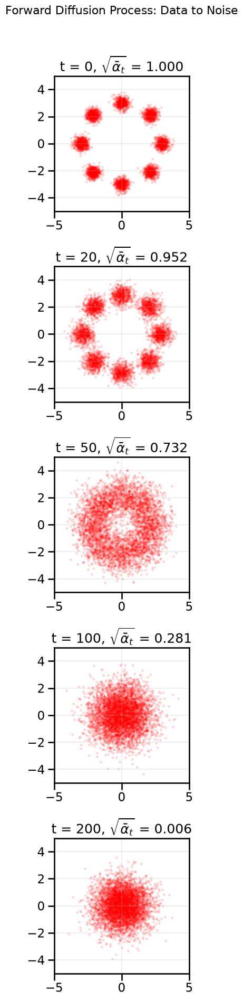

alpha_bar_T = 3.2e-05, sqrt(alpha_bar_T) = 0.0056


In [4]:
#| code-fold: false
def get_alphas(timesteps=200, beta_start=0.0001, beta_end=0.1):
    """Create the noise schedule parameters alpha and alpha_bar."""
    betas = torch.linspace(beta_start, beta_end, timesteps)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, axis=0)
    return alphas, alphas_cumprod

def forward_diffusion_sample(x_0, t, alphas_cumprod, device="cpu"):
    """Takes an datapoint and a timestep and returns the noisy version."""
    noise = torch.randn_like(x_0)
    sqrt_alphas_cumprod_t = torch.sqrt(alphas_cumprod[t])[:, None]
    sqrt_one_minus_alphas_cumprod_t = torch.sqrt(1. - alphas_cumprod[t])[:, None]

    # send to device
    sqrt_alphas_cumprod_t = sqrt_alphas_cumprod_t.to(device)
    sqrt_one_minus_alphas_cumprod_t = sqrt_one_minus_alphas_cumprod_t.to(device)
    noise = noise.to(device)

    # Equation for x_t
    noisy_x = sqrt_alphas_cumprod_t * x_0 + sqrt_one_minus_alphas_cumprod_t * noise
    return noisy_x, noise

# Get the noise schedule
T = 200
alphas, alphas_cumprod = get_alphas(timesteps=T)

# Visualize the forward process
data_tensor = torch.tensor(data, dtype=torch.float32).to(device)

fig, axes = plt.subplots(5, 1, figsize=(6, 20))
plot_times = [0, 20, 50, 100, T]  # x_0 is the data; x_t (t >= 1) uses schedule index t - 1

for i, t_int in enumerate(plot_times):
    if t_int == 0:
        noisy_data = data
        alpha_bar_t = torch.tensor(1.0)
    else:
        t = torch.full((data_tensor.shape[0],), t_int - 1, dtype=torch.long)
        noisy_data, _ = forward_diffusion_sample(data_tensor, t, alphas_cumprod, device=device)
        noisy_data = noisy_data.cpu().numpy()
        alpha_bar_t = alphas_cumprod[t_int - 1]

    ax = axes[i]
    ax.scatter(noisy_data[:, 0], noisy_data[:, 1], s=5, alpha=0.1, color="red")
    ax.set_title(rf"t = {t_int}, $\sqrt{{\bar\alpha_t}}$ = {alpha_bar_t.sqrt():.3f}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

fig.suptitle("Forward Diffusion Process: Data to Noise", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()
print(f"alpha_bar_T = {alphas_cumprod[-1]:.1e}, sqrt(alpha_bar_T) = {alphas_cumprod[-1].sqrt():.4f}")

As you can see, the forward process gradually transforms the structured ring of Gaussians into a fuzzy, isotropic Gaussian blob. By $t = 50$ the eight modes have blurred into one ring. By $t = 100$ the ring is gone. At each intermediate step $t$, we have a distribution $p_t(x)$ that is smoother and more spread out than the original data distribution. This gives us a family of intermediate densities where score estimation is much easier and better-behaved, which is the key insight we will leverage next.

## The Reverse Process and Multi-Scale Score Estimation

The magic of diffusion models lies in the **reverse process**. If we can reverse the arrow of time, we can start from pure noise $x_T \sim \mathcal{N}(0, I)$ and gradually denoise it step-by-step to generate a clean sample $x_0$.

It turns out that the reverse of the diffusion process is also a diffusion, described by a stochastic differential equation (SDE). While the full derivation is beyond our scope, the key insight is that the "drift" of this reverse process depends on the score of the noisy data distribution at that time, $\nabla_{x_t} \log p_t(x_t)$.

$$
dx_t = f(x_t, t) dt + g(t)^2 \nabla_{x_t} \log p_t(x_t) dt + g(t) d\bar{W}_t
$$

where $f(x_t, t)$ is the drift term of the forward process, $g(t)$ is the diffusion coefficient, and $d\bar{W}_t$ is a Wiener process in reverse time. For the time being, lets put aside the exact forms of $f$ and $g$ and focus on the score term.


This is the crucial connection: **to reverse the diffusion, we need to know the score function at every noise level $t$**. This is why diffusion models are essentially **time-conditional score models**. Instead of learning a single score function for a fixed $\sigma$, we will learn a single neural network $s_\theta(x_t, t)$ that can estimate the score for any noisy sample $x_t$ at any time $t$.

Let's visualize what these score fields look like at different noise levels. We'll train separate score networks for low, medium, and high noise to see how the target vector field changes. Each one is the single-noise network from above. We train it on samples of $p_t$, that is, on $x_t = \sqrt{\bar{\alpha}_t}\, x_0 + \sigma_t \epsilon$ with $\sigma_t = \sqrt{1 - \bar{\alpha}_t}$. The arrows in the figure show only the direction of the learned score. This keeps the structure near the data visible.

In the three fields, the arrows point to different things:

- **Low Noise (t is small):** The arrows point to the eight modes of the original data.
- **Medium Noise (t is medium):** The modes have blurred into one ring, and the arrows point to the ring rather than to individual modes.
- **High Noise (t is large):** The data is almost pure noise, so the score is that of a standard Gaussian. The arrows point straight to the origin, and the field shows no trace of the ring.

In [5]:
#| code-fold: false
# Map t to sigma. The variance of the noise added at time t is 1 - alpha_bar_t.
# So, sigma_t = sqrt(1 - alpha_bar_t)
# Times to visualize: low, medium and high noise (x_t uses schedule index t - 1)
viz_times = {'Low': 10, 'Medium': 50, 'High': T}
score_nets = {}

for level, t_int in viz_times.items():
    alpha_bar_t = alphas_cumprod[t_int - 1].item()
    sigma_t = (1. - alpha_bar_t) ** 0.5
    name = rf"{level} Noise (t={t_int}, $\sigma_t$={sigma_t:.2f})"
    print(f"Training for {level.lower()} noise, t={t_int}, sigma_t={sigma_t:.3f}")
    score_nets[name] = (train_simple_score_net(sigma=sigma_t, alpha_bar=alpha_bar_t), alpha_bar_t, sigma_t)


Training for low noise, t=10, sigma_t=0.153
Finished training score network with sigma=0.153
Training for medium noise, t=50, sigma_t=0.682
Finished training score network with sigma=0.682
Training for high noise, t=200, sigma_t=1.000
Finished training score network with sigma=1.000


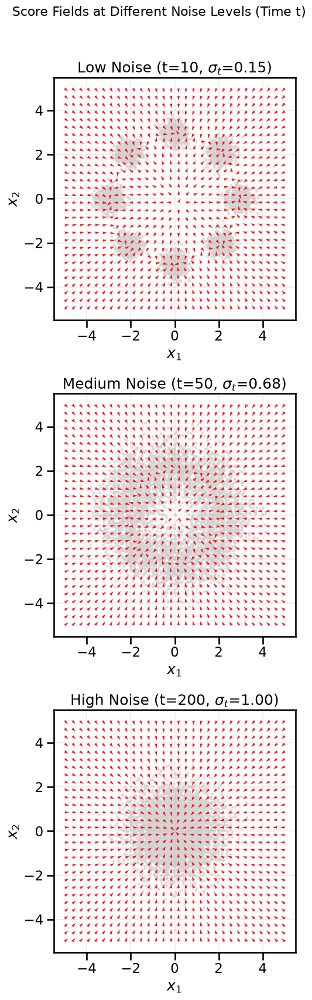

In [6]:
# Create a grid for visualization
xx_levels, yy_levels = np.meshgrid(np.linspace(-5, 5, 30), np.linspace(-5, 5, 30))
grid_points_levels = torch.tensor(np.stack([xx_levels.ravel(), yy_levels.ravel()], axis=1), dtype=torch.float32, device=device)

# Plot the score fields over samples of p_t at the same noise level
fig, axes = plt.subplots(3, 1, figsize=(6, 18))
for i, (name, (net, alpha_bar_t, sigma_t)) in enumerate(score_nets.items()):
    net.eval()
    with torch.no_grad():
        scores_level = net(grid_points_levels).cpu().numpy()
    # Show the direction of the score only: far from the data the score is so large that, drawn to scale,
    # those arrows would hide the structure near the data
    scores_level = scores_level / np.linalg.norm(scores_level, axis=1, keepdims=True)
    x_t_samples = np.sqrt(alpha_bar_t) * data + sigma_t * np.random.randn(*data.shape)

    ax = axes[i]
    ax.scatter(x_t_samples[:, 0], x_t_samples[:, 1], s=5, color='lightgrey', alpha=0.5)
    ax.quiver(grid_points_levels[:, 0].cpu(), grid_points_levels[:, 1].cpu(), scores_level[:, 0], scores_level[:, 1], color='red', width=0.008, alpha=0.9)
    ax.set_title(name)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

fig.suptitle("Score Fields at Different Noise Levels (Time t)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()


## How Training Works (Denoising Score Matching Perspective)

Now that we understand the goal—learning a time-conditional score function—how do we train such a model? The answer is a natural extension of the Denoising Score Matching (DSM) objective we learned in the previous chapter.

Instead of training on a single noise level, we train on **all noise levels simultaneously**. We'll create a single neural network, $s_\theta(x_t, t)$, that takes both the noisy data $x_t$ and the timestep $t$ as input. The network's job is to predict the score of the noisy data distribution $p_t(x)$ at that specific time.

The loss function is almost identical to the one for simple DSM from last chapter, but now we take the expectation over uniformly sampled time $t$ as well:

$$
L(\theta) = \mathbb{E}_{x_0 \sim p_{data}, t \sim \text{Uniform}(0, T), \epsilon \sim \mathcal{N}(0, I)} \left[ \left\| s_\theta(x_t, t) - \nabla_{x_t} \log p_t(x_t | x_0) \right\|^2 \right]
$$

Just like before, the target score $\nabla_{x_t} \log p_t(x_t | x_0)$ is analytically known and simplifies to $-\frac{\epsilon}{\sqrt{1 - \bar{\alpha}_t}}$. So, our practical loss becomes:

$$
L(\theta) = \mathbb{E}_{x_0, t, \epsilon} \left[ \left\| s_\theta(\sqrt{\bar{\alpha}_t}x_0 + \sqrt{1-\bar{\alpha}_t}\epsilon, t) + \frac{\epsilon}{\sqrt{1 - \bar{\alpha}_t}} \right\|^2 \right]
$$

In many modern diffusion model implementations, it's more common to reparameterize the network to predict the noise $\epsilon$ directly, rather than the score. Let's call this network $\epsilon_\theta(x_t, t)$. The relationship is:
$s_\theta(x_t, t) = -\frac{\epsilon_\theta(x_t, t)}{\sqrt{1 - \bar{\alpha}_t}}$. Substituting this into the loss function gives a simpler, more stable objective:

$$
L(\theta) = \mathbb{E}_{x_0, t, \epsilon} \left[ \left\| \epsilon_\theta(\sqrt{\bar{\alpha}_t}x_0 + \sqrt{1-\bar{\alpha}_t}\epsilon, t) - \epsilon \right\|^2 \right]
$$

This is (again) just a simple L2 regression! The network takes a noisy sample $x_t$ and its corresponding time $t$ and learns to predict the exact noise $\epsilon$ that was added to the original sample $x_0$.

### The Training Pipeline

The training process looks like this for each step:

1.  **Sample Data:** Pick a clean sample $x_0$ from the training data (our ring of Gaussians).
2.  **Sample Time:** Pick a schedule index uniformly at random from $\{0, 1, ..., T-1\}$. Index $t-1$ gives $x_t$.
3.  **Add Noise:** Create the noisy sample $x_t$ using the forward process equation: $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon$.
4.  **Predict Noise:** Feed $x_t$ and $t$ into the neural network $\epsilon_\theta(x_t, t)$ to get the predicted noise.
5.  **Compute Loss:** Calculate the Mean Squared Error between the network's prediction and the true noise $\epsilon$.
6.  **Update:** Backpropagate the loss and update the network's weights.

By repeating this process, the single network $\epsilon_\theta$ learns the entire time-varying vector field.

Epoch 0, Loss: 0.8458
Epoch 50, Loss: 0.3476
Epoch 100, Loss: 0.3332
Epoch 150, Loss: 0.3110
Epoch 200, Loss: 0.2933
Epoch 250, Loss: 0.3088
Epoch 299, Loss: 0.3116
Training complete.


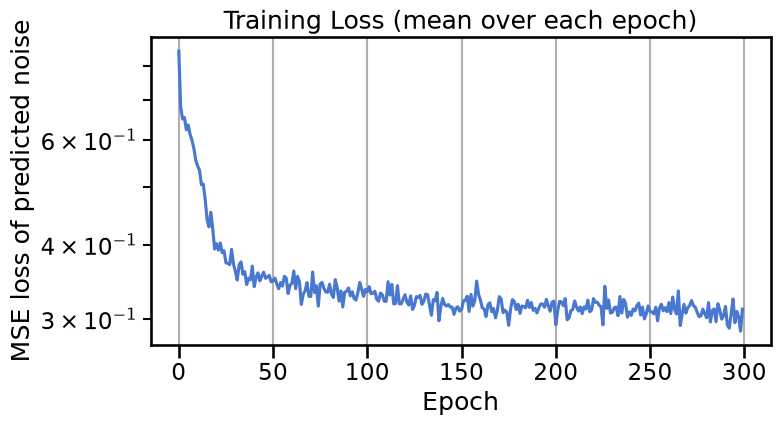

In [7]:
#| code-fold: false
class DiffusionModel(nn.Module):
    def __init__(self, n_steps=200, time_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2) # Predicts the noise
        )

    def forward(self, x, t):
        t_emb = self.time_embed(t)
        x_in = torch.cat([x, t_emb], dim=-1)
        return self.net(x_in)

# Training parameters
T = 200 # Number of diffusion steps
lr = 1e-3
n_epochs = 300
batch_size = 256

# Data
loader = make_loader(data, batch_size=batch_size)

# Model and optimizer
model = DiffusionModel(n_steps=T).to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)
alphas, alphas_cumprod = get_alphas(timesteps=T)

# Training loop
losses = []  # mean loss of each epoch
for epoch in range(n_epochs):
    epoch_losses = []
    for (x_0,) in loader:
        x_0 = x_0.to(device)

        # 1. Sample a random time t
        t = torch.randint(0, T, (x_0.shape[0],), device=device).long()

        # 2. Create noisy sample x_t and get the true noise
        x_t, noise = forward_diffusion_sample(x_0, t, alphas_cumprod, device)

        # 3. Predict the noise
        predicted_noise = model(x_t, t)

        # 4. Calculate the loss
        loss = nn.functional.mse_loss(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_losses.append(loss.item())

    losses.append(np.mean(epoch_losses))
    if epoch % 50 == 0 or epoch == n_epochs - 1:
        print(f"Epoch {epoch}, Loss: {losses[-1]:.4f}")

print("Training complete.")

# Plot the loss curve
plt.figure(figsize=(8, 4))
plt.plot(range(n_epochs), losses)
plt.title("Training Loss (mean over each epoch)")
plt.xlabel("Epoch")
plt.ylabel("MSE loss of predicted noise")
plt.yscale('log')
plt.grid(True)
plt.show()

The loss levels off near 0.3. It does not go to zero, even if we train for longer, because part of the noise cannot be predicted. At small $t$, the added noise is a small part of $x_t$. The network cannot tell it apart from the spread of the data. At large $t$, $x_t$ is almost all noise, so $\epsilon \approx x_t$ and the noise is easy to predict. The overall loss is the mean over all $t$. The figure below splits it into four bands of $t$. We compute it for the trained model on one fixed batch. The loss is 0.641 for $t = 1$ to 50, 0.493 for $t = 51$ to 100, 0.106 for $t = 101$ to 150 and 0.008 for $t = 151$ to 200. The loss per band is a quick way to check which noise levels a diffusion model has learned.

t =   1 to  50: loss 0.641
t =  51 to 100: loss 0.493
t = 101 to 150: loss 0.106
t = 151 to 200: loss 0.008


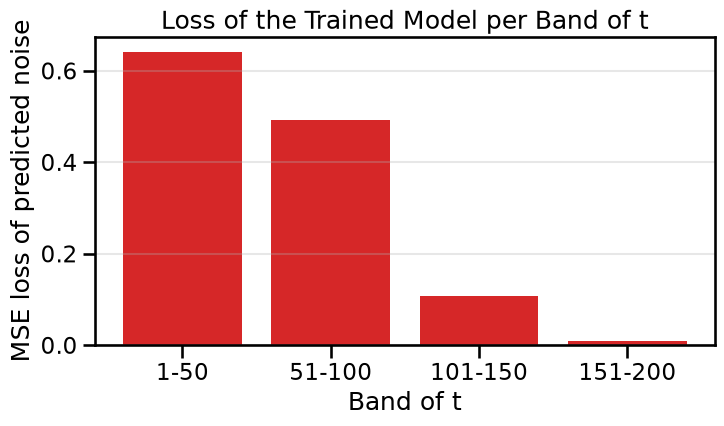

In [8]:
# Loss of the trained model in four bands of t, on one fixed batch
loss_bands = [(1, 50), (51, 100), (101, 150), (151, 200)]  # bands of t; x_t uses schedule index t - 1
band_gen = torch.Generator().manual_seed(0)  # its own generator, so the cells below draw the same random numbers
x_0_band = torch.tensor(data, dtype=torch.float32, device=device)
band_losses = []
with torch.no_grad():
    for lo, hi in loss_bands:
        t = torch.randint(lo - 1, hi, (x_0_band.shape[0],), generator=band_gen)
        eps = torch.randn(x_0_band.shape, generator=band_gen)
        alpha_bar_t = alphas_cumprod[t][:, None]
        x_t = alpha_bar_t.sqrt() * x_0_band + (1 - alpha_bar_t).sqrt() * eps
        band_losses.append(nn.functional.mse_loss(model(x_t, t), eps).item())
        print(f"t = {lo:3d} to {hi:3d}: loss {band_losses[-1]:.3f}")

plt.figure(figsize=(8, 4))
plt.bar([f"{lo}-{hi}" for lo, hi in loss_bands], band_losses, color='tab:red')
plt.title("Loss of the Trained Model per Band of t")
plt.xlabel("Band of t")
plt.ylabel("MSE loss of predicted noise")
plt.grid(True, axis='y', alpha=0.3)
plt.show()

## Generating Samples via Reverse Sampling

With our time-conditional noise predictor $\epsilon_\theta(x_t, t)$ fully trained, we can now perform the reverse process to generate new data. This is the most intuitive and visually satisfying part of diffusion models.

We start with pure Gaussian noise, $x_T \sim \mathcal{N}(0, I)$, and then iteratively "denoise" it by stepping backward in time from $t=T$ down to $t=0$, one step at a time. For the step from $x_t$ to $x_{t-1}$, we give the network the schedule index $t-1$. Each reverse step updates the sample's position based on the predicted noise (which is related to the score as we saw above).

The update rule for a single reverse step (from $t$ to $t-1$) is:

$$
x_{t-1} = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \epsilon_\theta(x_t, t) \right) + \sigma_t z
$$

where $z \sim \mathcal{N}(0, I)$ is new noise added at each step (for a stochastic sampler), and $\sigma_t$ is its standard deviation. The `reverse_sample` function below uses $\sigma_t^2 = \beta_t$. The conditional samplers later in the chapter use a slightly smaller value, $\sigma_t^2 = \beta_t (1 - \bar{\alpha}_{t-1}) / (1 - \bar{\alpha}_t)$. Both are standard choices, and they give almost the same samples. This equation looks complex, but the intuition is simple:

1.  **Predict Noise:** Use the network $\epsilon_\theta(x_t, t)$ to estimate the noise that was added to get to the current state $x_t$.
2.  **Estimate Clean Data:** Use the predicted noise to get a rough estimate of the original clean data, $x_0$.
3.  **Step Back:** Use this estimate to take one step backward in the diffusion process, arriving at a slightly less noisy sample, $x_{t-1}$.
4.  **Add Stochasticity:** Add a small amount of random noise to explore the distribution (this corresponds to the SDE sampler). If we omit this term, we get a deterministic sampler (an ODE).

Let's implement this reverse sampling process and watch as a cloud of random noise transforms into our target ring of Gaussians. This animation is the core "aha" moment for understanding how diffusion models work.

In [9]:
#| code-fold: false
@torch.no_grad()
def reverse_sample(model, n_samples=50, n_steps=T, initial_noise_scale=1.0):
    """Generate samples by running the reverse diffusion process.

    n_steps must be the number of steps T the model was trained with: it rebuilds that noise schedule."""
    model.eval()

    # Start with pure noise
    x = torch.randn(n_samples, 2, device=device) * initial_noise_scale

    # Store trajectory for animation
    trajectory = [x.cpu().numpy()]

    # Get noise schedule
    alphas, alphas_cumprod = get_alphas(timesteps=n_steps)
    betas = 1. - alphas

    for i in range(n_steps - 1, -1, -1):
        t = torch.full((n_samples,), i, device=device, dtype=torch.long)

        # Predict noise
        predicted_noise = model(x, t)

        # Get parameters for this timestep
        alpha_t = alphas[t][:, None]
        alpha_t_cumprod = alphas_cumprod[t][:, None]
        beta_t = betas[t][:, None]

        # The update rule
        coeff = (1. - alpha_t) / torch.sqrt(1. - alpha_t_cumprod)
        x = (1. / torch.sqrt(alpha_t)) * (x - coeff * predicted_noise)

        if i > 0:
            # Add noise for stochastic sampling
            variance = beta_t
            noise = torch.randn_like(x) * torch.sqrt(variance)
            x = x + noise

        trajectory.append(x.cpu().numpy())

    return x.cpu().numpy(), np.array(trajectory)

# Generate samples and their trajectories
num_generated_samples = 5000
generated_samples, trajectory = reverse_sample(model,
                                               n_samples=num_generated_samples,
                                               n_steps=T)

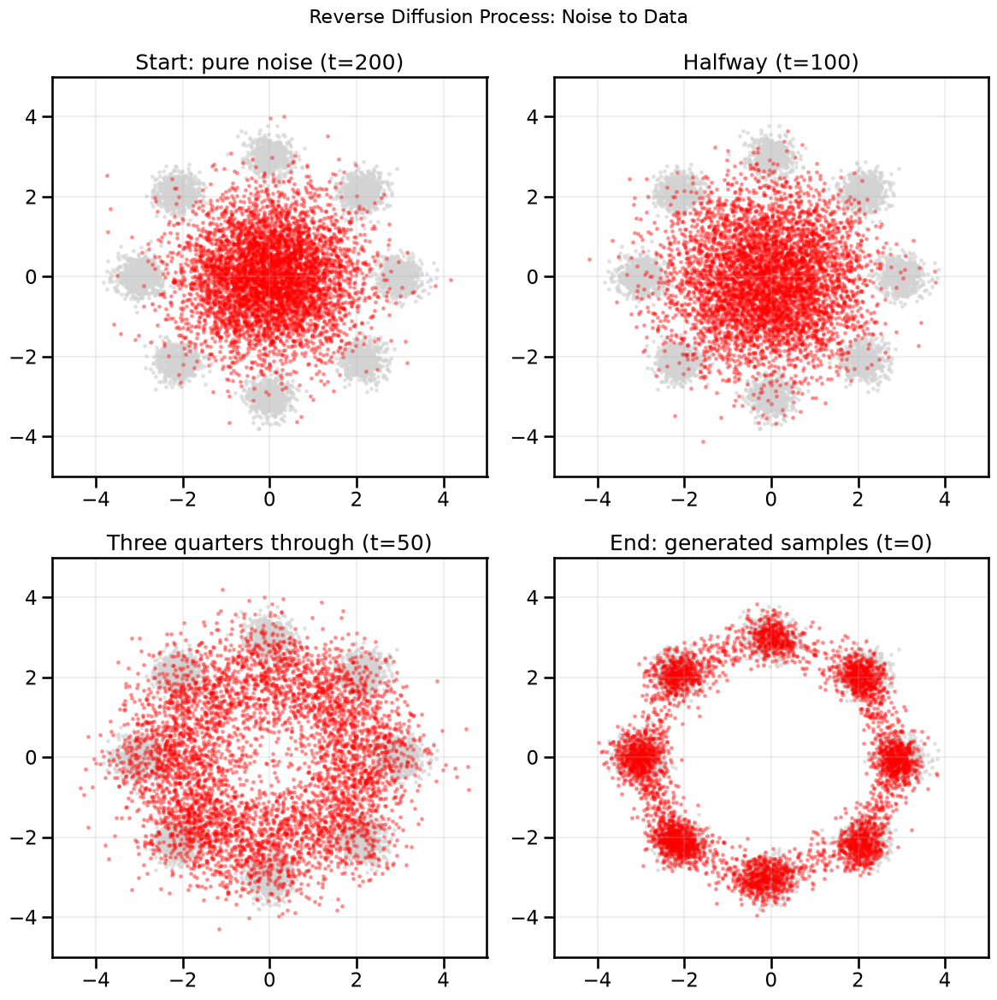

In [10]:
# Pick a random subset of the original data for background visualization
data_indices = np.random.choice(data.shape[0], size=num_generated_samples, replace=False)
data_subset = data[data_indices]

# Show samples at three stages of the reverse process. trajectory[k] holds the samples
# after k reverse steps, at diffusion time t = T - k: trajectory[0] is the pure noise x_T, trajectory[T] the final x_0.
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
stages = [0, T//2, 3*T//4, T]
stage_titles = [f'Start: pure noise (t={T})', f'Halfway (t={T - T//2})', f'Three quarters through (t={T - 3*T//4})', 'End: generated samples (t=0)']
for ax, stage, title in zip(axes.ravel(), stages, stage_titles):
    ax.scatter(data_subset[:, 0], data_subset[:, 1], s=5, color='lightgrey', alpha=0.5)
    ax.scatter(trajectory[stage][:, 0], trajectory[stage][:, 1], s=5, color="red", alpha=0.3)
    ax.set_title(title)
    #ax.axis('equal')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.grid(True, alpha=0.2)
fig.suptitle("Reverse Diffusion Process: Noise to Data", fontsize=16)
plt.tight_layout()
plt.show()


At $t = 100$, halfway through the reverse process, the samples still look like noise. A fuzzy ring appears around $t = 50$, where $\sigma_t \approx 0.7$. The eight modes separate only in the last 50 steps. We can also animate the entire reverse diffusion process to visualize how samples evolve from pure noise to structured data:

In [11]:
fig_anim, ax_anim = plt.subplots(figsize=(8, 8))

def update_anim(frame):
    ax_anim.clear()

    # Plot the original data samples in the background, for comparison
    ax_anim.scatter(data_subset[:, 0], data_subset[:, 1], s=5, color='lightgrey', alpha=0.5)

    # Plot the current state of the samples (trajectory[frame] is at diffusion time t = T - frame)
    ax_anim.scatter(trajectory[frame][:, 0], trajectory[frame][:, 1], s=10, color='red', alpha=0.1)

    ax_anim.set_title(f"Reverse Diffusion: t = {T - frame}")
    ax_anim.set_xlabel('$x_1$')
    ax_anim.set_ylabel('$x_2$')
    ax_anim.set_xlim(-7, 7)
    ax_anim.set_ylim(-7, 7)
    ax_anim.grid(True, alpha=0.2)

# Create and display the animation
# The number of frames is the number of steps in the trajectory
# We can skip frames to make the animation faster
skip_frames = 5
frames_anim = range(0, trajectory.shape[0], skip_frames)
ani_anim = FuncAnimation(fig_anim, update_anim, frames=frames_anim, repeat=False, interval=50)
plt.close(fig_anim) # Prevent static plot from showing
HTML(ani_anim.to_jshtml())

The animation illustrates the generative process: the points start as a random cloud and are gradually "guided" by the learned, time-varying score field. As time decreases, the field becomes sharper, pulling the points onto the intricate structure of original data distribution.

## Connection to Langevin Dynamics

How does this relate to the Langevin Dynamics we used in the previous chapter?

You can think of the reverse diffusion process as a more sophisticated, "annealed" version of Langevin Dynamics.

-   **Langevin Dynamics**, as we used it in the last chapter, follows one score field with a fixed step size. We learned that field at a single noise level $\sigma$. The sampler explores this one landscape locally, and the landscape never changes.
-   **Reverse Diffusion** follows a score that changes with $t$, so its landscape changes too. It starts on a very smooth, simple landscape (at high $t$) where the global structure is easy to find. As $t$ decreases, the landscape becomes more detailed, allowing the sampler to refine the samples it generates.

At $t \approx 0$, the reverse SDE step is mathematically very similar to a Langevin dynamics step on the true data score. So, diffusion models can be seen as a way to reliably initialize a sampler in a high-density region before switching to local exploration. This is why they are so effective at generating high-quality, diverse samples.

## Conditional Generation Examples

Diffusion models naturally extend to conditional generation by providing additional conditioning information to the denoising network. This is particularly powerful because the time-conditional architecture already accepts auxiliary inputs, making it straightforward to add class labels, continuous attributes, or even images as conditioning signals.

The key modification is to pass both the noisy data $x_t$, the timestep $t$, and the conditioning variable $y$ to the denoising network: $\epsilon_\theta(x_t, t, y)$. During training, we learn to predict noise conditioned on $y$, and during sampling, we can specify $y$ to control what we generate.

This approach has been used successfully in many applications, including class-conditional image generation (e.g., ImageNet), text-to-image synthesis (e.g., DALL-E 2, Stable Diffusion), and more.

### Conditional Example A — One-Hot Mode Conditioning

We'll condition the diffusion model on the discrete mode index using one-hot encoding. The conditioning vector is concatenated with the noisy data and time embedding before passing through the network.

In [12]:
#| code-fold: false
from gen_models_utilities import make_conditional_loader_onehot, plot_conditional_samples_discrete

# Conditional Diffusion Model
class ConditionalDiffusionModel(nn.Module):
    def __init__(self, n_steps=200, time_emb_dim=16, label_dim=8, hidden_dim=128):
        super().__init__()
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim + label_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x, t, y):
        t_emb = self.time_embed(t)
        x_in = torch.cat([x, t_emb, y], dim=-1)
        return self.net(x_in)

def train_conditional_diffusion_onehot(
    data: np.ndarray, labels: np.ndarray, n_classes: int = 8,
    T: int = 200, lr: float = 1e-3, n_epochs: int = 5000, batch_size: int = 256, print_every: int = 500
):
    loader = make_conditional_loader_onehot(data, labels, batch_size, n_classes)
    model = ConditionalDiffusionModel(n_steps=T, label_dim=n_classes).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    alphas, alphas_cumprod = get_alphas(timesteps=T)
    losses = []

    for epoch in range(n_epochs):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            t = torch.randint(0, T, (xb.shape[0],), device=device).long()
            x_t, noise = forward_diffusion_sample(xb, t, alphas_cumprod, device)
            predicted_noise = model(x_t, t, yb)
            loss = nn.functional.mse_loss(predicted_noise, noise)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if epoch % print_every == 0:
            losses.append(loss.item())
            print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

    return model, alphas, alphas_cumprod, losses

# Conditional sampling function
@torch.no_grad()
def sample_conditional_diffusion(
    model: nn.Module, y: torch.Tensor, alphas: torch.Tensor, alphas_cumprod: torch.Tensor,
    n_samples: int = 100, T: int = 200
):
    model.eval()
    x = torch.randn(n_samples, 2, device=device)

    for t_idx in reversed(range(T)):
        t = torch.full((n_samples,), t_idx, device=device, dtype=torch.long)
        predicted_noise = model(x, t, y)

        alpha_t = alphas[t_idx]
        alpha_bar_t = alphas_cumprod[t_idx]

        # Compute mean of the reverse step
        if t_idx > 0:
            noise = torch.randn_like(x)
            alpha_bar_t_prev = alphas_cumprod[t_idx - 1]
            beta_t = 1 - alpha_t
            sigma_t = torch.sqrt(beta_t * (1 - alpha_bar_t_prev) / (1 - alpha_bar_t))
        else:
            noise = torch.zeros_like(x)
            sigma_t = 0.0

        x = (1 / torch.sqrt(alpha_t)) * (x - (1 - alpha_t) / torch.sqrt(1 - alpha_bar_t) * predicted_noise)
        x = x + sigma_t * noise

    return x.cpu().numpy()



# Ring of Gaussians with the mode labels, as a separate data set for the conditional examples
data_cond, y_ring = create_ring_gaussians(n_samples=5000, n_modes=8, radius=3.0, cluster_std=0.25)

# Train conditional diffusion
print("Training conditional diffusion model (one-hot)...")
cdiff_onehot, alphas_oh, alphas_cumprod_oh, losses_oh = train_conditional_diffusion_onehot(
    data_cond, y_ring, n_classes=8, T=200, lr=1e-3, n_epochs=200, batch_size=256, print_every=50
)

Training conditional diffusion model (one-hot)...
Epoch 0, Loss: 0.6930
Epoch 50, Loss: 0.1221
Epoch 100, Loss: 0.1093
Epoch 150, Loss: 0.1145


Let's generate conditional samples for each mode:

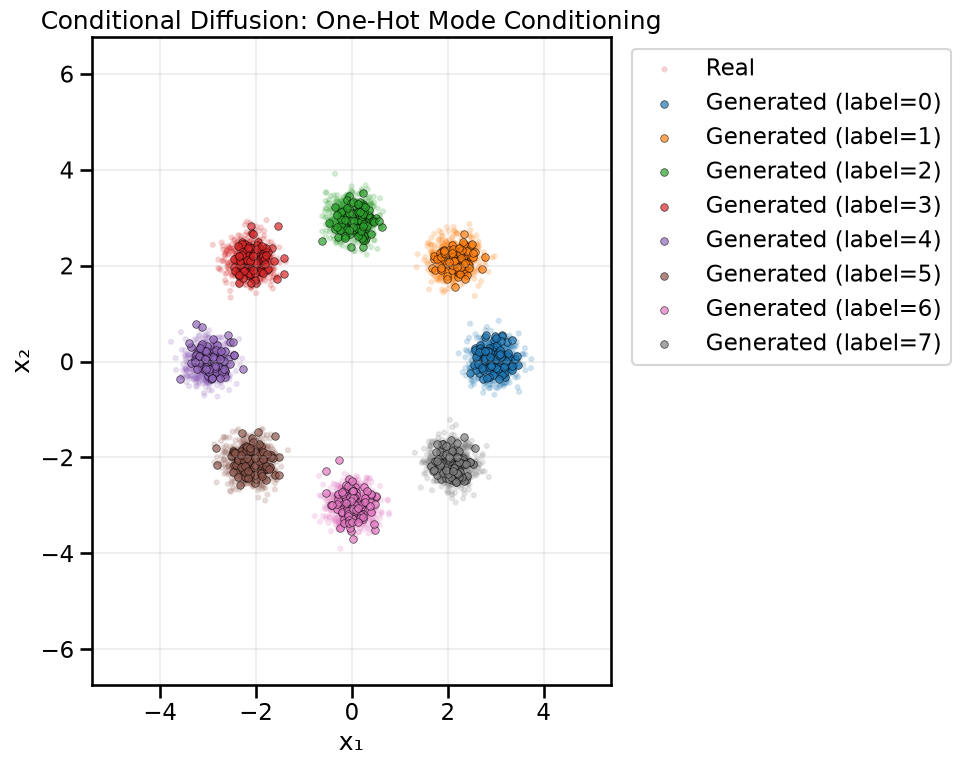

In [13]:
# Generate conditional samples for each mode
samples_by_label = {}
n_samples_per_mode = 100

for label in range(8):
    y = torch.nn.functional.one_hot(
        torch.full((n_samples_per_mode,), label, device=device), num_classes=8
    ).to(torch.float32)
    samples = sample_conditional_diffusion(cdiff_onehot, y, alphas_oh, alphas_cumprod_oh, n_samples=n_samples_per_mode, T=200)
    samples_by_label[label] = samples

plot_conditional_samples_discrete(
    samples_by_label, data_cond, y_ring, title="Conditional Diffusion: One-Hot Mode Conditioning"
)

### Conditional Example B — Continuous Radius Conditioning

Now let's condition the diffusion model on a continuous scalar—the radius. We'll embed the radius through a small MLP before concatenating it with the noisy data and time embedding.

In [14]:
#| code-fold: false
from gen_models_utilities import make_conditional_loader_radius, plot_conditional_samples_continuous

# Conditional Diffusion Model with radius embedding
class ConditionalDiffusionModelRadius(nn.Module):
    def __init__(self, n_steps=200, time_emb_dim=16, cond_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.cond_embed = nn.Sequential(
            nn.Linear(1, cond_emb_dim),
            nn.ReLU(),
            nn.Linear(cond_emb_dim, cond_emb_dim),
        )
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim + cond_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x, t, r):
        t_emb = self.time_embed(t)
        r_emb = self.cond_embed(r)
        x_in = torch.cat([x, t_emb, r_emb], dim=-1)
        return self.net(x_in)

def train_conditional_diffusion_radius(
    data: np.ndarray, T: int = 200, lr: float = 1e-3,
    n_epochs: int = 5000, batch_size: int = 256, print_every: int = 500
):
    loader = make_conditional_loader_radius(data, batch_size)
    model = ConditionalDiffusionModelRadius(n_steps=T).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    alphas, alphas_cumprod = get_alphas(timesteps=T)
    losses = []

    for epoch in range(n_epochs):
        for xb, rb in loader:
            xb, rb = xb.to(device), rb.to(device)
            t = torch.randint(0, T, (xb.shape[0],), device=device).long()
            x_t, noise = forward_diffusion_sample(xb, t, alphas_cumprod, device)
            predicted_noise = model(x_t, t, rb)
            loss = nn.functional.mse_loss(predicted_noise, noise)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if epoch % print_every == 0:
            losses.append(loss.item())
            print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

    return model, alphas, alphas_cumprod, losses

@torch.no_grad()
def sample_conditional_diffusion_radius(
    model: nn.Module, r: torch.Tensor, alphas: torch.Tensor, alphas_cumprod: torch.Tensor,
    n_samples: int = 100, T: int = 200
):
    model.eval()
    x = torch.randn(n_samples, 2, device=device)

    for t_idx in reversed(range(T)):
        t = torch.full((n_samples,), t_idx, device=device, dtype=torch.long)
        predicted_noise = model(x, t, r)

        alpha_t = alphas[t_idx]
        alpha_bar_t = alphas_cumprod[t_idx]

        if t_idx > 0:
            noise = torch.randn_like(x)
            alpha_bar_t_prev = alphas_cumprod[t_idx - 1]
            beta_t = 1 - alpha_t
            sigma_t = torch.sqrt(beta_t * (1 - alpha_bar_t_prev) / (1 - alpha_bar_t))
        else:
            noise = torch.zeros_like(x)
            sigma_t = 0.0

        x = (1 / torch.sqrt(alpha_t)) * (x - (1 - alpha_t) / torch.sqrt(1 - alpha_bar_t) * predicted_noise)
        x = x + sigma_t * noise

    return x.cpu().numpy()

# Train conditional diffusion with radius
print("Training conditional diffusion model (radius)...")
cdiff_radius, alphas_r, alphas_cumprod_r, losses_r = train_conditional_diffusion_radius(
    data_cond, T=200, lr=3e-3, n_epochs=300, batch_size=256, print_every=50
)

Training conditional diffusion model (radius)...
Epoch 0, Loss: 0.6609
Epoch 50, Loss: 0.2828
Epoch 100, Loss: 0.2549
Epoch 150, Loss: 0.2586
Epoch 200, Loss: 0.2637
Epoch 250, Loss: 0.2749


Let's generate samples at different radius values:

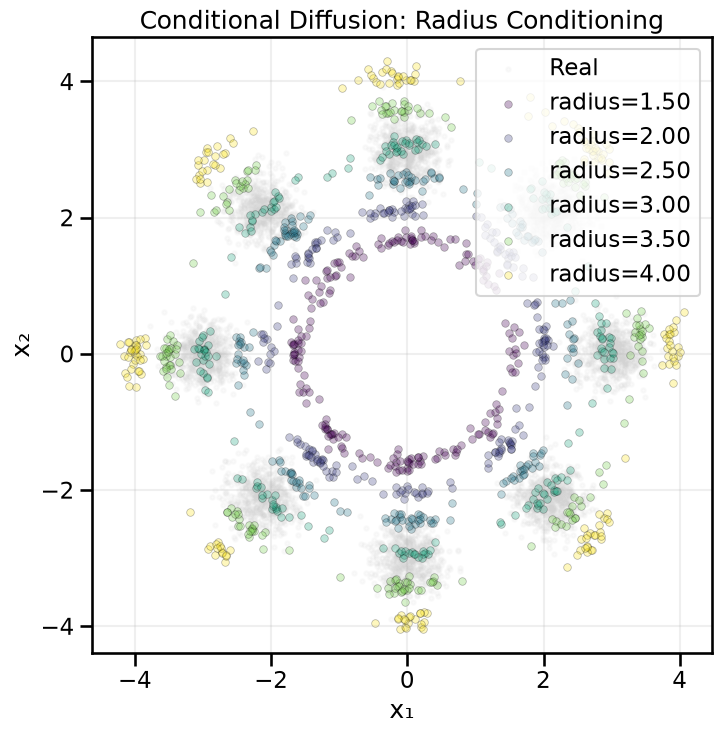

In [15]:
# Generate conditional samples for different radius values
samples_by_radius = {}
n_samples_per_radius = 200
radius_values = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]

for r_val in radius_values:
    r = torch.full((n_samples_per_radius, 1), r_val, device=device)
    samples = sample_conditional_diffusion_radius(cdiff_radius, r, alphas_r, alphas_cumprod_r, n_samples=n_samples_per_radius, T=200)
    samples_by_radius[r_val] = samples

plot_conditional_samples_continuous(
    samples_by_radius, data_cond, title="Conditional Diffusion: Radius Conditioning", value_name="radius"
)

Note that while these examples are simple, and thus work well for simple conditioning schemes where we just concatenate the conditioning vector, more complex conditioning (e.g., images or text) often requires specialized architectures like cross-attention layers or what are referred to as "guidance" methods (e.g., Classifier Guidance or Classifier-Free Guidance) to effectively incorporate the conditioning information. These techniques are beyond the scope of what I will cover in this introductory book but are important for state-of-the-art conditional diffusion models.

## Summary and Next Steps

-   **Diffusion Models as Time-Extended Score Models:** Diffusion models solve the problems of single-noise score matching by learning a score function across a continuum of noise levels.
-   **Forward Process:** Data is gradually noised into an isotropic Gaussian distribution, creating a series of well-behaved intermediate distributions $p_t(x)$.
-   **Reverse Process:** A time-conditional neural network, $\epsilon_\theta(x_t, t)$, learns to predict the noise at any given time $t$. This network is trained with a simple MSE loss.
-   **Generative Sampling:** By starting with pure noise and running the process in reverse, we can iteratively denoise the samples, guiding them onto the data manifold to produce realistic new data.

While we used a toy example of a 2D Ring of Gaussians to explore diffusion models, the general principles behind them are applied to generate high-resolution images, audio, and other complex data, often using more sophisticated network architectures like U-Nets. At their core, the concepts of the forward and reverse processes remain exactly the same. The main downside of Diffusion models is their sampling time. Every sample needs one network evaluation per reverse step, which is 200 evaluations here. The sampler we used also adds new noise at every step, so it is stochastic -- that is, our results will change every time we run the model. In the next chapter, we will explore an idea that borrows concepts from both score matching and Continous Normalizing Flows to define deterministic, yet flexible generative models called **Flow Matching**.

## Exercises

The exercises use the chapter's data, functions and noise schedule, so run the chapter's cells first. The titles give rough time estimates.

Exercise 1 is about a diffusion model with a bug. Below is the class `DiffusionModelEx1`. The cell after it trains this model and the chapter's `DiffusionModel` on the ring data. Both use the chapter's noise schedule, training loop and seed, and both train for 150 epochs (about a minute). The cell then draws two figures. The first shows the training loss of each model and its loss in four bands of $t$. The second shows 2000 samples from each model's reverse process at $t = 200$, $133$, $67$, and $0$. In both figures, the top row shows the healthy plots of the chapter's model, and the bottom row shows the unhealthy plots of `DiffusionModelEx1`.

In [16]:
#| code-fold: false
#| code-line-numbers: true
class DiffusionModelEx1(nn.Module):
    def __init__(self, n_steps=200, time_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2) # Predicts the noise
        )

    def forward(self, x, t):
        return self.net(x)

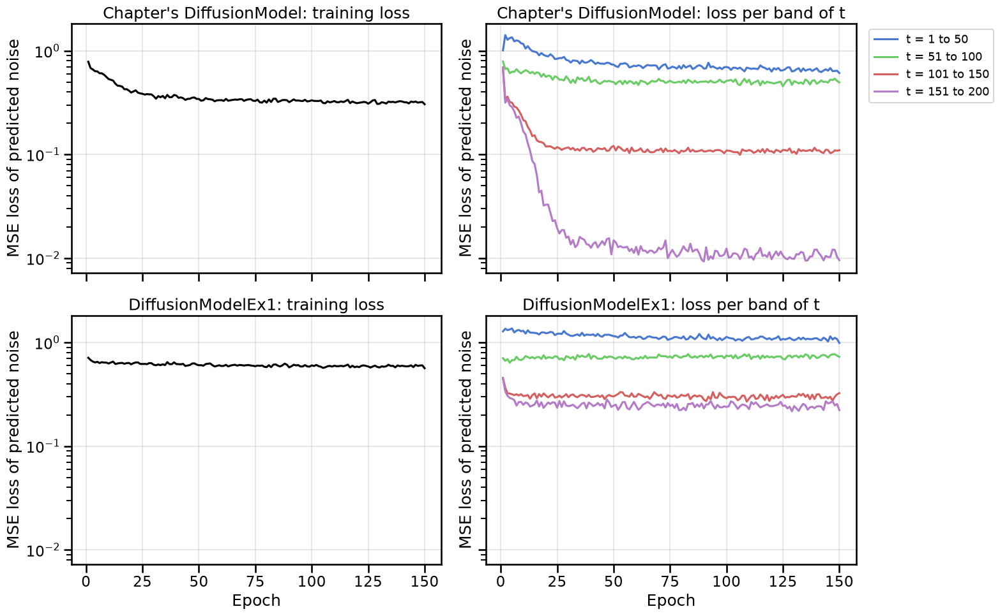

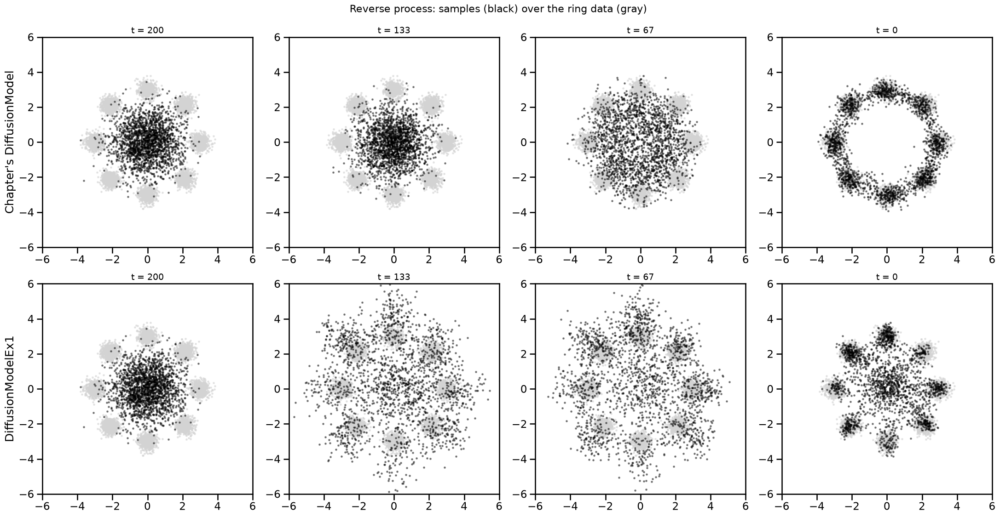

In [17]:
#| echo: false
# Figures for Exercise 1: the chapter's DiffusionModel and DiffusionModelEx1, trained the same way
EX_SEED = 42
EX1_EPOCHS = 150
EX1_BANDS = [(1, 50), (51, 100), (101, 150), (151, 200)]  # bands of t; x_t uses schedule index t - 1
EX1_STEPS = [0, 67, 133, 200]  # reverse steps taken; the samples are then at t = T - steps
_, alphas_cumprod_ex1 = get_alphas(timesteps=T)


def train_with_bands(model, n_epochs=EX1_EPOCHS, batch_size=256, lr=1e-3, seed=EX_SEED):
    # The chapter's training loop; also records the mean loss in each band of t, per epoch
    torch.manual_seed(seed)
    loader_ex1 = make_loader(data, batch_size=batch_size)
    optimizer_ex1 = optim.Adam(model.parameters(), lr=lr)
    epoch_loss, band_loss = [], []
    for epoch in range(n_epochs):
        batch_losses = []
        band_sum = np.zeros(len(EX1_BANDS))
        band_count = np.zeros(len(EX1_BANDS))
        for (x_0,) in loader_ex1:
            t = torch.randint(0, T, (x_0.shape[0],))
            x_t, noise = forward_diffusion_sample(x_0, t, alphas_cumprod_ex1)
            predicted_noise = model(x_t, t)
            loss = nn.functional.mse_loss(predicted_noise, noise)
            optimizer_ex1.zero_grad()
            loss.backward()
            optimizer_ex1.step()
            batch_losses.append(loss.item())
            per_sample = ((predicted_noise - noise) ** 2).mean(dim=1).detach()
            for k, (lo, hi) in enumerate(EX1_BANDS):
                in_band = (t >= lo - 1) & (t < hi)
                band_sum[k] += per_sample[in_band].sum().item()
                band_count[k] += in_band.sum().item()
        epoch_loss.append(np.mean(batch_losses))
        band_loss.append(band_sum / band_count)
    return np.array(epoch_loss), np.array(band_loss)


ex1_models, ex1_loss, ex1_bands, ex1_traj = {}, {}, {}, {}
for name, model_class in [("Chapter's DiffusionModel", DiffusionModel), ('DiffusionModelEx1', DiffusionModelEx1)]:
    torch.manual_seed(EX_SEED)
    ex1_models[name] = model_class(n_steps=T)
    ex1_loss[name], ex1_bands[name] = train_with_bands(ex1_models[name])
    torch.manual_seed(EX_SEED)
    _, ex1_traj[name] = reverse_sample(ex1_models[name], n_samples=2000, n_steps=T)

# Losses: total, and per band of t
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
for row, name in enumerate(ex1_models):
    axes[row, 0].plot(np.arange(1, EX1_EPOCHS + 1), ex1_loss[name], color='k')
    axes[row, 0].set_ylabel('MSE loss of predicted noise')
    axes[row, 0].set_title(f'{name}: training loss')
    for k, (lo, hi) in enumerate(EX1_BANDS):
        axes[row, 1].plot(np.arange(1, EX1_EPOCHS + 1), ex1_bands[name][:, k], label=f't = {lo} to {hi}')
    axes[row, 1].set_title(f'{name}: loss per band of t')
    for ax in axes[row]:
        ax.set_yscale('log')
        ax.set_ylabel('MSE loss of predicted noise')
        ax.grid(True, alpha=0.3)
axes[0, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=13)
for ax in axes[1]:
    ax.set_xlabel('Epoch')
plt.tight_layout()
plt.show()

# Reverse-process snapshots
fig, axes = plt.subplots(2, 4, figsize=(22, 11.5))
for row, name in enumerate(ex1_models):
    for col, steps in enumerate(EX1_STEPS):
        ax = axes[row, col]
        ax.scatter(data[:, 0], data[:, 1], s=4, color='lightgrey', alpha=0.5)
        ax.scatter(ex1_traj[name][steps][:, 0], ex1_traj[name][steps][:, 1], s=4, color='k', alpha=0.4)
        ax.set_xlim(-6, 6)
        ax.set_ylim(-6, 6)
        ax.set_aspect('equal')
        ax.set_title(f't = {T - steps}', fontsize=14)
    axes[row, 0].set_ylabel(name)
fig.suptitle('Reverse process: samples (black) over the ring data (gray)', fontsize=16)
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 1 (~15 min): What is wrong with this diffusion model?
- (a) Which line of `DiffusionModelEx1` is likely causing the problem? What does the model fail to do because of it, and why does that matter for a diffusion model?
- (b) Which features of the unhealthy plots led you to that line? Why does that line cause them?
:::

---

Exercise 2 looks at what a noise prediction tells us about the clean data. The chapter's network predicts the noise $\epsilon$. If we solve the forward process for $x_0$, any noise prediction also gives a guess of the clean point:

$$
\hat{x}_0(x_t) = \frac{x_t - \sqrt{1 - \bar\alpha_t}\, \hat\epsilon}{\sqrt{\bar\alpha_t}}.
$$

We use the one-dimensional mixture of a wide and a narrow Gaussian from Exercise 3 of the previous chapter,

$$
p(x) = \frac{0.7}{0.6\sqrt{2\pi}} \exp\left( -\frac{(x + 2)^2}{2 \cdot 0.6^2} \right) + \frac{0.3}{0.25\sqrt{2\pi}} \exp\left( -\frac{(x - 2)^2}{2 \cdot 0.25^2} \right).
$$

Under the forward process, each component stays Gaussian. So $p_t$ is again a mixture of two Gaussians, with means $\sqrt{\bar\alpha_t}\, \mu_k$ and variances $\bar\alpha_t \sigma_k^2 + 1 - \bar\alpha_t$. We know its score in closed form, and with it the ideal noise prediction $\hat\epsilon = -\sqrt{1 - \bar\alpha_t}\, \nabla_x \log p_t(x)$. The cell below computes the guess $\hat{x}_0$ from this $\hat\epsilon$ with the chapter's schedule. It plots the guess against $x_t$ at five times.

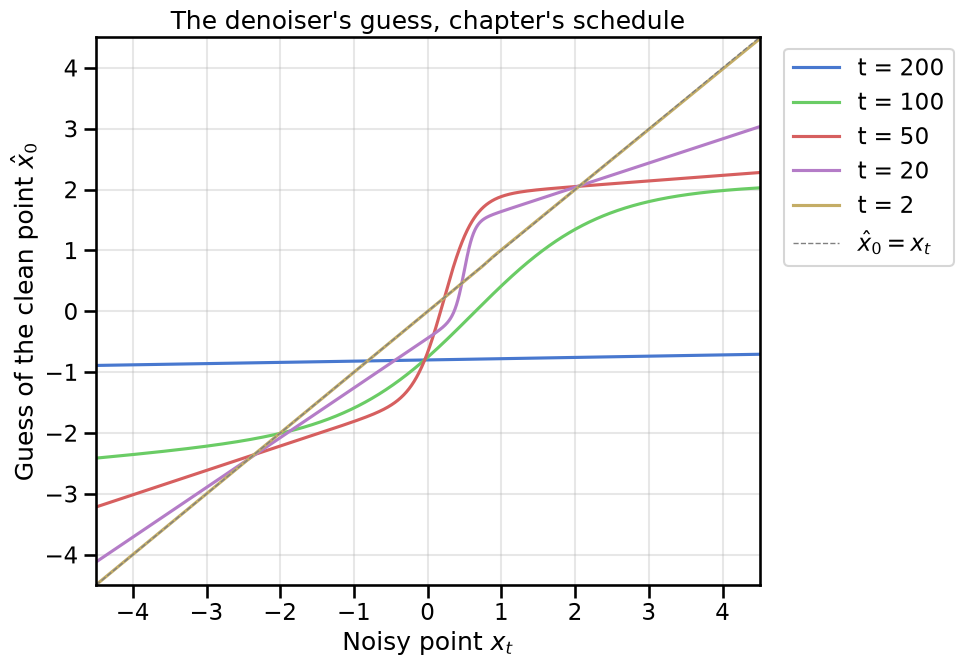

In [18]:






#| echo: false
# Figure for Exercise 2: the denoiser's guess of the clean point, from the exact noise of a 1D mixture
MIX_W = np.array([0.7, 0.3])
MIX_MU = np.array([-2.0, 2.0])
MIX_SD = np.array([0.6, 0.25])
EX2_TIMES = [200, 100, 50, 20, 2]
alphas_cumprod_ex2 = get_alphas(timesteps=T)[1].double().numpy()  # the chapter's schedule


def mix_t_components(x, alpha_bar):
    # Weighted components of p_t: means sqrt(alpha_bar) mu_k, variances alpha_bar sd_k^2 + 1 - alpha_bar
    means = np.sqrt(alpha_bar) * MIX_MU
    var = alpha_bar * MIX_SD ** 2 + 1 - alpha_bar
    return MIX_W * np.exp(-0.5 * (x[:, None] - means) ** 2 / var) / np.sqrt(2 * np.pi * var), means, var


def mix_t_score(x, alpha_bar):
    # d/dx log p_t(x): each component's score, weighted by its share of p_t(x)
    comps, means, var = mix_t_components(x, alpha_bar)
    resp = comps / comps.sum(axis=1, keepdims=True)
    return (resp * (-(x[:, None] - means) / var)).sum(axis=1)


def alpha_bar_at(alphas_cumprod_1d, t):
    # alpha_bar of x_t; t = 0 is the data
    return 1.0 if t == 0 else alphas_cumprod_1d[t - 1]


xs_1d = np.linspace(-4.5, 4.5, 1801)
fig, ax = plt.subplots(figsize=(10, 7))
for t in EX2_TIMES:
    alpha_bar_t = alpha_bar_at(alphas_cumprod_ex2, t)
    eps_hat = -np.sqrt(1 - alpha_bar_t) * mix_t_score(xs_1d, alpha_bar_t)
    x0_hat = (xs_1d - np.sqrt(1 - alpha_bar_t) * eps_hat) / np.sqrt(alpha_bar_t)
    ax.plot(xs_1d, x0_hat, label=f't = {t}')
ax.plot(xs_1d, xs_1d, color='0.5', linestyle='--', linewidth=1, label=r'$\hat{x}_0 = x_t$')
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-4.5, 4.5)
ax.set_xlabel('Noisy point $x_t$')
ax.set_ylabel(r'Guess of the clean point $\hat{x}_0$')
ax.set_title("The denoiser's guess, chapter's schedule")
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~10 min): What the denoiser predicts
- (a) At $t = 200$ the guess is almost the same for every $x_t$. Why, and why is it at that value?
- (b) At $t = 50$ the curve is close to a step between two plateaus. Why? Why is the plateau on the right flatter than the one on the left?
- (c) At $t = 2$ the guess is almost $x_t$ itself. Why?
- (d) In Exercise 1, the chapter's model had its lowest loss at high $t$ and its highest loss at low $t$. Compare this with (a) and (c). Why is the noise easy to predict when the clean point is hard to guess, and hard to predict when the clean point is easy to guess?
:::